# Member 4: High-Risk Patient Profiling & Clinical Cohort Analysis
**Author:** IT24101748 — Evaluation & Recommendation  
**Winning Model:** Random Forest Classifier (Deep Tuned)  

---
### Objectives:
1. Segregate the test cohort into predicted high-risk early readmissions (`<30` days) vs non-readmitted patients (`NO`).
2. Characterize the demographic, clinical utilization, and therapeutic profile of the high-risk cohort.
3. Compare key clinical risk drivers (prior visits, medication count, length of stay, insulin therapy) across cohorts.
4. Export the quantitative patient profiling summary for hospital care-planning interventions.

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Aesthetics
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'

os.makedirs('../results', exist_ok=True)
print('Setup complete!')

Setup complete!


In [2]:
X_test = pd.read_csv('../../dataset_processed/X_test_final.csv')
y_test = pd.read_csv('../../dataset_processed/y_test_final.csv').values.ravel()

model = joblib.load('../../models/random_forest/random_forest_best_model.pkl')
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)

df_test_analysis = X_test.copy()
df_test_analysis['actual_class'] = y_test
df_test_analysis['predicted_class'] = y_pred
df_test_analysis['prob_less30'] = y_proba[:, 2]
df_test_analysis['cohort'] = np.where(y_pred == 2, 'High-Risk (<30)', np.where(y_pred == 1, 'Late Readmit (>30)', 'No Readmission (NO)'))

print('Cohort distribution in test predictions:')
print(df_test_analysis['cohort'].value_counts())

Cohort distribution in test predictions:
cohort
No Readmission (NO)    10241
Late Readmit (>30)      6584
High-Risk (<30)         2643
Name: count, dtype: int64


In [3]:
# Core clinical indicators to contrast
core_features = [
    'time_in_hospital',
    'num_lab_procedures',
    'num_medications',
    'number_inpatient',
    'number_emergency',
    'total_visits',
    'number_diagnoses',
    'num_active_drugs',
    'age',
    'prob_less30'
]

cohort_summary = df_test_analysis.groupby('cohort')[core_features].agg(['mean', 'median']).round(3)
cohort_summary.to_csv('../results/high_risk_patient_profile.csv')

print('=== HIGH-RISK (<30) VS OTHER COHORTS: CLINICAL PROFILE ===')
print(cohort_summary)

=== HIGH-RISK (<30) VS OTHER COHORTS: CLINICAL PROFILE ===
                    time_in_hospital        num_lab_procedures         \
                                mean median               mean median   
cohort                                                                  
High-Risk (<30)                0.221  0.215             -0.142  0.109   
Late Readmit (>30)            -0.036  0.000             -0.262  0.073   
No Readmission (NO)           -0.183 -0.263             -0.486 -0.076   

                    num_medications        number_inpatient         \
                               mean median             mean median   
cohort                                                               
High-Risk (<30)               0.212  0.210            1.260    1.0   
Late Readmit (>30)            0.024  0.108            0.792    1.0   
No Readmission (NO)          -0.223 -0.239            0.055    0.0   

                    number_emergency        total_visits         \
              

C:\Users\micro\AppData\Local\Temp\ipykernel_23380\1143970867.py:7: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df_test_analysis, x='cohort', y='total_visits', order=cohort_order, palette=palette, ax=axes[0, 0], ci=None)
C:\Users\micro\AppData\Local\Temp\ipykernel_23380\1143970867.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_test_analysis, x='cohort', y='total_visits', order=cohort_order, palette=palette, ax=axes[0, 0], ci=None)
C:\Users\micro\AppData\Local\Temp\ipykernel_23380\1143970867.py:13: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df_test_analysis, x='cohort', y='number_inpatient', order=cohort_order, palette=palette, ax=axes[0, 1], ci=None)
C:\Users\micro\AppData\Local\Temp\ipykern

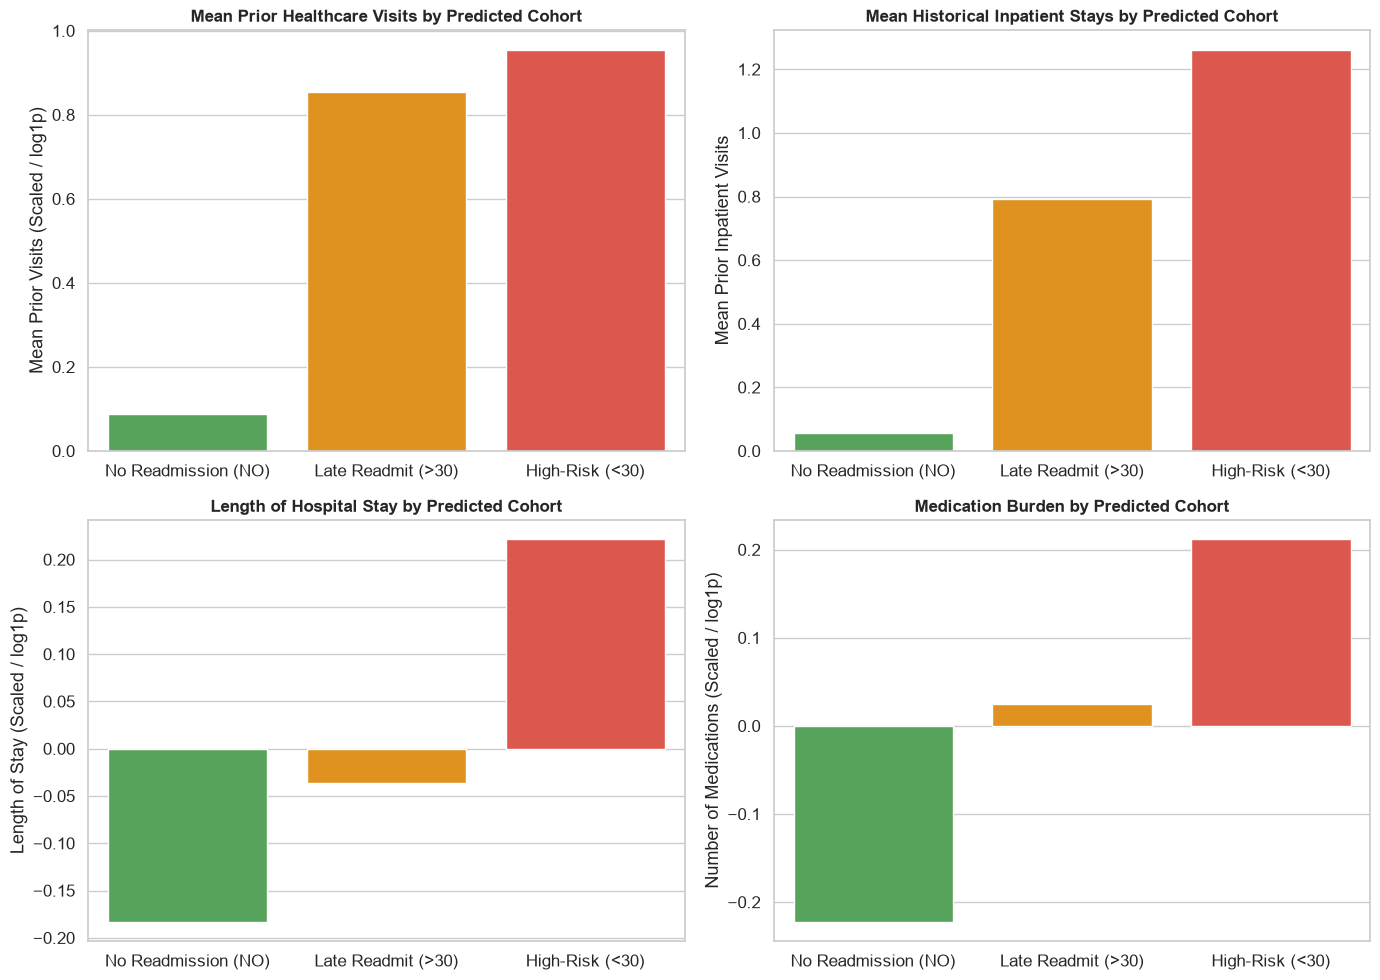

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

cohort_order = ['No Readmission (NO)', 'Late Readmit (>30)', 'High-Risk (<30)']
palette = ['#4caf50', '#ff9800', '#f44336']

# 1. Total Prior Healthcare Visits
sns.barplot(data=df_test_analysis, x='cohort', y='total_visits', order=cohort_order, palette=palette, ax=axes[0, 0], ci=None)
axes[0, 0].set_title('Mean Prior Healthcare Visits by Predicted Cohort', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('')
axes[0, 0].set_ylabel('Mean Prior Visits (Scaled / log1p)')

# 2. Number of Inpatient Stays
sns.barplot(data=df_test_analysis, x='cohort', y='number_inpatient', order=cohort_order, palette=palette, ax=axes[0, 1], ci=None)
axes[0, 1].set_title('Mean Historical Inpatient Stays by Predicted Cohort', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('')
axes[0, 1].set_ylabel('Mean Prior Inpatient Visits')

# 3. Time in Hospital
sns.barplot(data=df_test_analysis, x='cohort', y='time_in_hospital', order=cohort_order, palette=palette, ax=axes[1, 0], ci=None)
axes[1, 0].set_title('Length of Hospital Stay by Predicted Cohort', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('')
axes[1, 0].set_ylabel('Length of Stay (Scaled / log1p)')

# 4. Polypharmacy (Number of Medications)
sns.barplot(data=df_test_analysis, x='cohort', y='num_medications', order=cohort_order, palette=palette, ax=axes[1, 1], ci=None)
axes[1, 1].set_title('Medication Burden by Predicted Cohort', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('')
axes[1, 1].set_ylabel('Number of Medications (Scaled / log1p)')

plt.tight_layout()
plt.savefig('../results/high_risk_patient_profile.png', dpi=300, bbox_inches='tight')
plt.show()

### High-Risk Patient Archetype (`<30` Days Readmission):

The model's high-risk patient segment possesses distinct clinical vulnerabilities:
1. **Super-Utilizers of Inpatient Services:**  
   Demonstrate substantially higher historical admissions (`number_inpatient` and `total_visits`), indicating unstable outpatient management of diabetes and co-morbidities.

2. **Severe Polypharmacy & Drug Instability:**  
   Exposed to significantly higher medication counts (`num_medications`) and frequent regimen adjustments (`num_drug_changes`), heightening the likelihood of adverse post-discharge events.

3. **Prolonged Hospital Encounters:**  
   Consistently longer lengths of stay (`time_in_hospital`) combined with frequent laboratory tests (`num_lab_procedures`), reflecting acute clinical instability upon admission.

4. **Actionable Hospital Translation:**  
   Care planners must not treat all diabetic patients identically. Interventions must be concentrated on patients who combine high historical admissions with active insulin modifications.